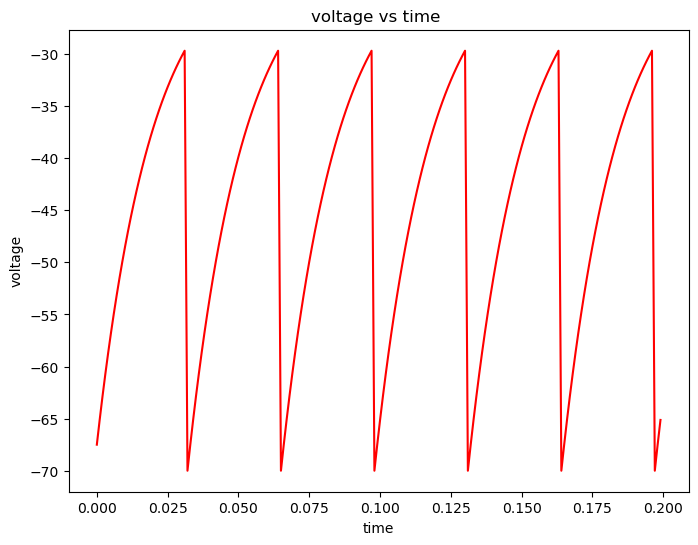

In [15]:
# Basic Leaky - fire- Integrate model under the supply of constant current
import numpy as np
import matplotlib.pyplot as plt
T = -30 # Threshold voltage
R = - 70 # Rest potential
V = -70 # potential at time t
k = 0.02 # relaxation time
r = 1 # resistance
I = 50 # constant current
dt = 0.001 # time step
Time = [] # to store time
Volt = [] # to store voltage
fig, ax = plt.subplots(figsize=(8,6))
for t in range(200):
    time=t*dt
    Time.append(time)
    if V<T and V>=R:
        dv = ((-V + R + r*I)/k)*dt # euler's method
        V+=dv
        Volt.append(V)
    elif V>=T:
        V = R
        Volt.append(V)
        
ax.plot(Time, Volt, color = "red")
ax.set_title("voltage vs time ")
ax.set_xlabel("time")
ax.set_ylabel("voltage")
plt.show()


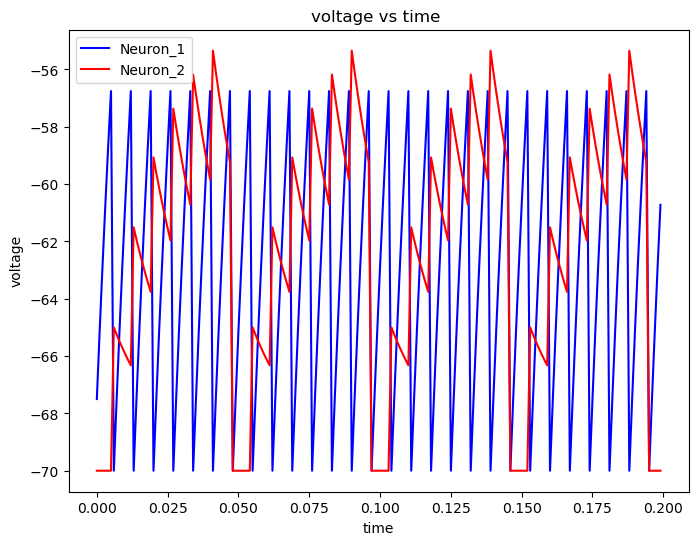

In [16]:
#LIF Model for two neuron system in which first one reciving constant current and second one recieves through synapses during action potential firing in neuron 1.
import numpy as np
import matplotlib.pyplot as plt
V_pre = -70 # voltage of neuron 1 that is pre-synaptic
V_post = -70 # # voltage of neuron 2 that is post-synaptic
R = -70 # Resting potential
k_1 = 0.02 # Relaxation time for neuron 1(Presynaptic)
k_2= 0.02 #  Relaxation time for neuron 1(Postsynaptic)
T = -55 # Threshold voltage
i = 50 # Constant current to neuron 1
r = 1 # Resistance
syn_weight = 5 # Addition of voltage when neuron 1 fires
dt = 0.001 # time step
pot_1= [] # recording voltage for neuron 1
pot_2=[] # recording voltage for neuron 1
Time=[]
fig, ax = plt.subplots(figsize=(8,6))
for t in range(200):
    time = t*dt
    Time.append(time)
    # differential equation, use of euler method
    # 1st neuron
    dV_pre = ((-V_pre + R + r*i)/k_1)*dt
    V_pre+=dV_pre
   # 2nd neuron
    dV_post = ((-V_post+R)/k_2)*dt
    V_post+=dV_post
   # At Synapses
    if V_pre>=T:
        V_pre = R
       
        V_post+= syn_weight
       
    if V_post>=T:
        V_post = R
    pot_1.append(V_pre)
    pot_2.append(V_post)
        
ax.plot(Time, pot_1, label="Neuron_1", color = "blue")
ax.plot(Time, pot_2, label="Neuron_2", color = "red")
ax.set_title("voltage vs time ")
ax.set_xlabel("time")
ax.set_ylabel("voltage")
ax.legend()
plt.show()    


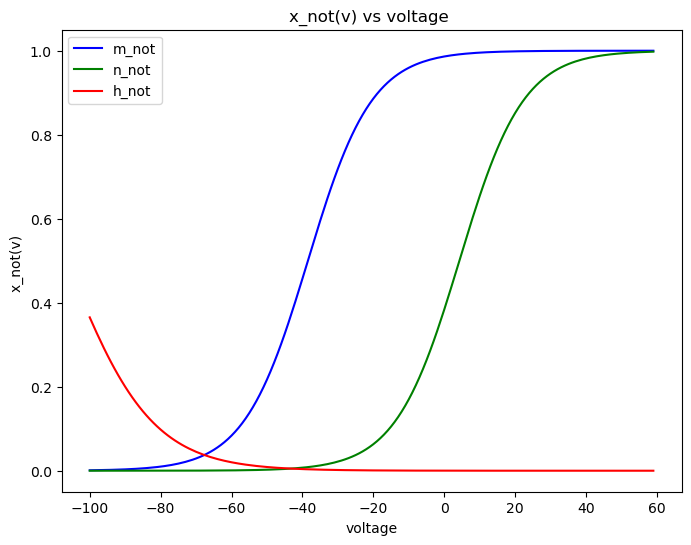

In [17]:
# From Hudgkin Huxley model, How m, n,h (gating variable) changes as function of voltage
import numpy as np
import matplotlib.pyplot as plt
Volt = [] 
m_values = []
n_values = []
h_values = []

fig, ax = plt.subplots(figsize=(8,6))
for v in range(-100, 60):
    V = v+ 1e-6
    Volt.append(v)
    # equation for m, n, h
    m = ((0.182*(V+35))/(1 - np.exp(-(V+35)/9)))/((0.182*(V+35))/(1 - np.exp(-(V+35)/9)) + (-0.124*(V+35))/(1 - np.exp((V+35)/9)))
    n = ((0.02*(V-25))/(1 - np.exp(-(V-25)/9)))/((0.02*(V-25))/(1 - np.exp(-(V-25)/9)) + (-0.002*(V-25))/(1 - np.exp((V-25)/9)))
    h =  (1/(1 + np.exp(-(V+62)/6)))/(1/(1 + np.exp(-(V+62)/6)) + (4*np.exp((V+90)/12))/(1 + np.exp(-(V+62)/6)))
    m_values.append(m)
    n_values.append(n)
    h_values.append(h)
    
ax.plot(Volt, m_values, label = "m_not", color = "blue")
ax.plot(Volt, n_values,  label = "n_not",  color = "green")
ax.plot(Volt, h_values, label = "h_not", color = "red")
ax.set_title("x_not(v) vs voltage ")
ax.set_xlabel("voltage")
ax.set_ylabel("x_not(v) ")
ax.legend()
plt.show()    
# x_not follows m, n, h


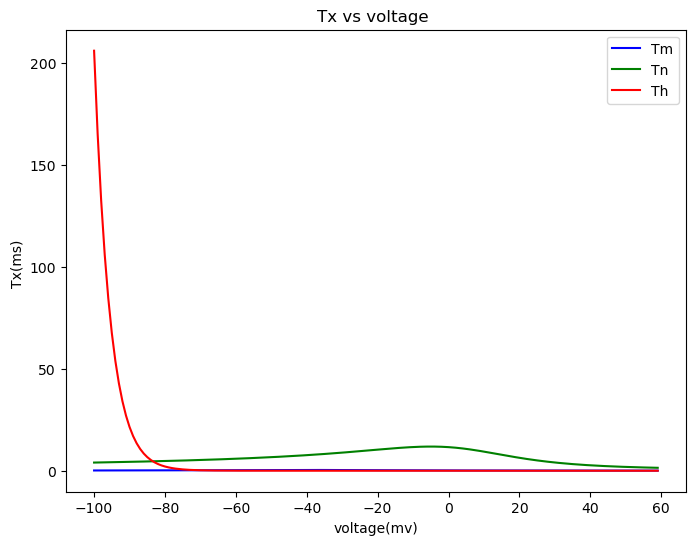

In [18]:
# From Hudgkin Huxley model, How time constant for m, n,h (gating variable) changes as function of voltage
import numpy as np
import matplotlib.pyplot as plt
Volt = []
Tm_values = []# Time constant for different voltage
Tn_values = []
Th_values = []

fig, ax = plt.subplots(figsize=(8,6))
for v in range(-100, 60):
    V = v +1e-6
    Volt.append(v)
    Tm = 1/((0.182*(V+35))/(1 - np.exp(-(V+35)/9)) + (-0.124*(V+35))/(1 - np.exp((V+35)/9)))
    Tn = 1/((0.02*(V-25))/(1 - np.exp(-(V-25)/9)) + (-0.002*(V-25))/(1 - np.exp((V-25)/9)))
    Th = 1/(1/(1 + np.exp(-(V+62)/6)) + (4*np.exp((V+90)/12))/(1 + np.exp(-(V+62)/6)))
    Tm_values.append(Tm)
    Tn_values.append(Tn)
    Th_values.append(Th)
    
ax.plot(Volt, Tm_values, label = "Tm", color = "blue")
ax.plot(Volt, Tn_values, label = "Tn",  color = "green")
ax.plot(Volt, Th_values, label = "Th", color = "red")
ax.set_title("Tx vs voltage ")
ax.set_xlabel("voltage(mv)")
ax.set_ylabel("Tx(ms) ")
ax.legend()
plt.show()    


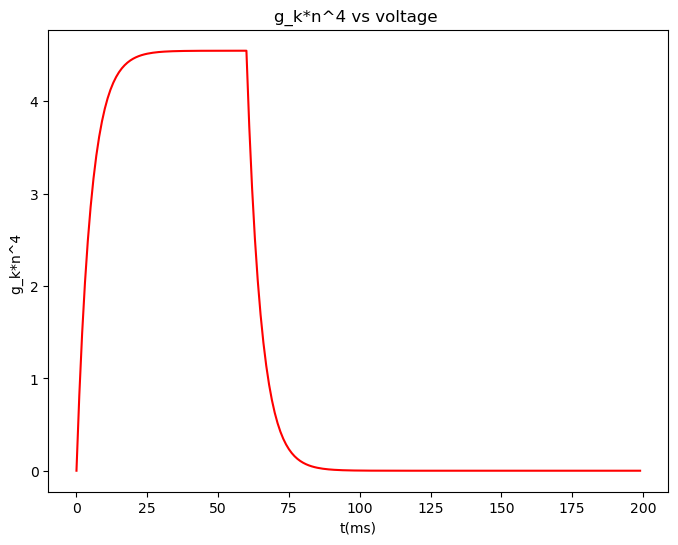

In [19]:
#  From Hudgkin Huxley model, the dynamics of conductance of potassium channel as function of time
import numpy as np
import matplotlib.pyplot as plt
time =[]
Ct = [] #Conductance
g_k = 5 # maximum conductance
k= 60 # time around which conductance reaches its maximum value
fig, ax = plt.subplots(figsize=(8,6))
for t in range(200):
    time.append(t)
    if t<=k: # upto this moment current is constantly provided
        c = g_k*(0.909 + (0.00045-0.909)*np.exp(-t/5.05))
    else: #After switching of current the trajectory of cunductance
        c = g_k*(0.00045 + (-0.00045+0.909)*np.exp(-(t-k)/5.05))
    
    Ct.append(c)
ax.plot(time, Ct, color = "red")
ax.set_title("g_k*n^4 vs voltage ")
ax.set_xlabel("t(ms)")
ax.set_ylabel("g_k*n^4 ")
plt.show()    



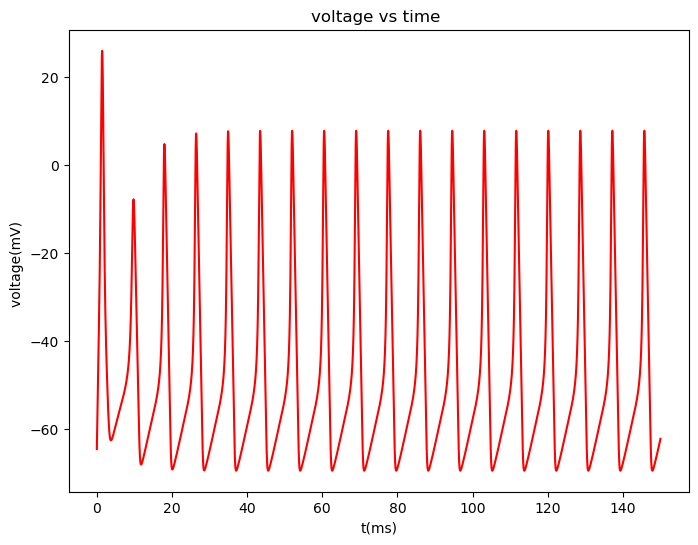

In [20]:
# HH-Model: how voltage will change under the supply of constant current
import numpy as np
import matplotlib.pyplot as plt
i = 50 # constant current
g_Na = 120 # Max. conductance of sodium channel
g_K = 36 # Max. conductance of potassium channel
g_L = 0.3 # Max. conductance for the aggregate of other channels
dt = 0.01 # time step
volt = []
Time = []
E_Na = 50 # Reversal potential of sodium channel in mV 
E_K =-77  # Reversal potential of potassium channel in mV
E_L = -54.4 # Reversal potential of aggregate of other channels channel in mV
V = -65 + 1e-6 # Starting potential
T = -55 # Threshold voltage
R = -65 # Resting potential
C = 1 # time constant for membrane acting as capacitor
M = 0.0498 # Max. activity of gating variable m at resting potential
N = 0.00045 # Max. activity of gating variable n at resting potential
H = 0.0302 # Max. activity of gating variable h at resting potential
fig, ax = plt.subplots(figsize=(8,6))
for t in range(15000):
    time = t*dt
    Time.append(time)
    # Standard Hodgkin-Huxley rate equations 
    alpha_m = 0.1 * (V + 40) / (1 - np.exp(-(V + 40) / 10))
    beta_m = 4.0 * np.exp(-(V + 65) / 18)

    alpha_n = 0.01 * (V + 55) / (1 - np.exp(-(V + 55) / 10))
    beta_n = 0.125 * np.exp(-(V + 65) / 80)

    alpha_h = 0.07 * np.exp(-(V + 65) / 20)
    beta_h = 1.0 / (1.0 + np.exp(-(V + 35) / 10))
    
    # Calculation of time constant at each voltage
    T_m = 1/ (alpha_m + beta_m)
    T_n = 1/ (alpha_n + beta_n)
    T_h = 1/ (alpha_h + beta_h)
   # Calculation of gating variable in terms of voltage 
    m = alpha_m/(alpha_m + beta_m)
    n = alpha_n/(alpha_n + beta_n)
    h = alpha_h/(alpha_h + beta_h)
   # Differntial equations for gating variable (exponential euler's method)
    M = m + (M - m) * np.exp(-dt / T_m)
    N = n + (N - n) * np.exp(-dt / T_n)
    H = h + (H - h) * np.exp(-dt / T_h)
    # Differential equation for voltage
    du =( i - ( g_Na*M**3*H*(V - E_Na) + g_K*N**4*(V - E_K) + g_L*(V-E_L)))*dt/C
    V+= du 
    volt.append(V)
   
ax.plot(Time, volt, color = "red")
ax.set_title("voltage vs time ")
ax.set_xlabel("t(ms)")
ax.set_ylabel("voltage(mV) ")
plt.show()  
        


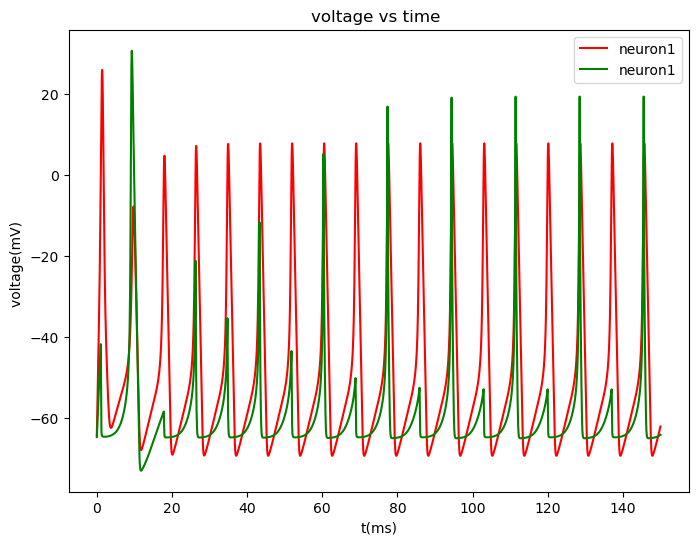

In [21]:
# Synapses analysis
# HH model of two neurons, neuron 1 is presynaptic neuron and neuron 2 is postsynaptic neuron
import numpy as np
import matplotlib.pyplot as plt
i = 50 # Constant current to neuron 1
i_2 = 20 # Constant current to neuron 2
g_Na = 120 # Max. conductance of sodium channel
g_K = 36 # Max. conductance of potassium channel
g_L = 0.3  # Max. conductance for the aggregate of other channels
dt = 0.01 # time step
V_1 = -65 + 1e-6 # Initiation for neuron 1
V_2 = -65 + 1e-6 # Initiation for neuron 2
volt_1 = [] # voltage holder for neuron 1
volt_2 = [] #voltage holder for neuron 2
Time = [] # time holder
# Reversal potential
E_Na = 50 # in mV 
E_K =-77  # in mV
E_L = -54.4 # in mV
T = -55 # Threshold
R = -65 # Resting potential
S = 0 # Initiation of synaptic weight
g_max = 200 # Maximum conductance of synaptic channel
C = 1 # time constant for membrane acting as capacitor
t_spike = -1000 # to avoid the false synapses
# Maximum activity of gating variable at rest 
M = 0.0498
N = 0.00045
H = 0.0302
M2 = 0.0498
N2 = 0.00045
H2 = 0.0302

E_inh = -65 # Reversal potential for synaptic channel
T_s = 1 # Time constant for synaptic channel
fig, ax = plt.subplots(figsize=(8,6))
for t in range(15000):
    time = t*dt
    Time.append(time)
    #1 neuron
    
    alpha_m = 0.1 * (V_1 + 40) / (1 - np.exp(-(V_1 + 40) / 10))
    beta_m = 4.0 * np.exp(-(V_1 + 65) / 18)

    alpha_n = 0.01 * (V_1 + 55) / (1 - np.exp(-(V_1 + 55) / 10))
    beta_n = 0.125 * np.exp(-(V_1 + 65) / 80)

    alpha_h = 0.07 * np.exp(-(V_1 + 65) / 20)
    beta_h = 1.0 / (1.0 + np.exp(-(V_1 + 35) / 10))
    T_m = 1/ (alpha_m + beta_m)
    T_n = 1/ (alpha_n + beta_n)
    T_h = 1/ (alpha_h + beta_h)
    
    m = alpha_m/(alpha_m + beta_m)
    n = alpha_n/(alpha_n + beta_n)
    h = alpha_h/(alpha_h + beta_h)

    M = m + (M - m) * np.exp(-dt / T_m)
    N = n + (N - n) * np.exp(-dt / T_n)
    H = h + (H - h) * np.exp(-dt / T_h)
    
    # 2nd neuron 
    alpha_m2 = 0.1 * (V_2 + 40) / (1 - np.exp(-(V_2 + 40) / 10))
    beta_m2 = 4.0 * np.exp(-(V_2 + 65) / 18)

    alpha_n2 = 0.01 * (V_2 + 55) / (1 - np.exp(-(V_2 + 55) / 10))
    beta_n2 = 0.125 * np.exp(-(V_2 + 65) / 80)

    alpha_h2 = 0.07 * np.exp(-(V_2 + 65) / 20)
    beta_h2 = 1.0 / (1.0 + np.exp(-(V_2 + 35) / 10))
    T_m2 = 1/ (alpha_m2 + beta_m2)
    T_n2 = 1/ (alpha_n2 + beta_n2)
    T_h2 = 1/ (alpha_h2 + beta_h2)
    
    m2 = alpha_m2/(alpha_m2 + beta_m2)
    n2 = alpha_n2/(alpha_n2 + beta_n2)
    h2 = alpha_h2/(alpha_h2 + beta_h2)
    
    M2 = m2 + (M2 - m2) * np.exp(-dt / T_m2)
    N2 = n2 + (N2 - n2) * np.exp(-dt / T_n2)
    H2 = h2 + (H2 - h2) * np.exp(-dt / T_h2)
    
    du_1 =( i - ( g_Na*M**3*H*(V_1 - E_Na) + g_K*N**4*(V_1 - E_K) + g_L*(V_1-E_L)))*dt/C
    V_1+= du_1
    
    # Synapses
    if V_1>=0 and V_prev<0: # Recording of time when firing occured in neuron 1
        t_spike = time
    delta_t = time - t_spike
    if t_spike > -500: # dynamics of conductance of synaptic channel after spike intiation
        g_inh = g_max*(delta_t / T_s) * np.exp(-delta_t / T_s)
    else:
        g_inh = 0.0
        
   
    V_prev = V_1
        
    i_inh = g_inh*(V_2 - E_inh) # synaptic current after each spike 
    # change in voltage of neuron 2 membrane after spike intiation in neuron 1
    du_2 =(i_2 -i_inh - ( g_Na*M2**3*H2*(V_2 - E_Na) + g_K*N2**4*(V_2 - E_K) + g_L*(V_2-E_L)))*dt/C
    V_2+= du_2
      
   
       
  
    volt_1.append(V_1)
    volt_2.append(V_2)       
        
   
ax.plot(Time, volt_1, label = "neuron1", color = "red")
ax.plot(Time, volt_2, label = "neuron1", color = "green")
ax.set_title("voltage vs time ")
ax.set_xlabel("t(ms)")
ax.set_ylabel("voltage(mV) ")
plt.legend()
plt.show()  

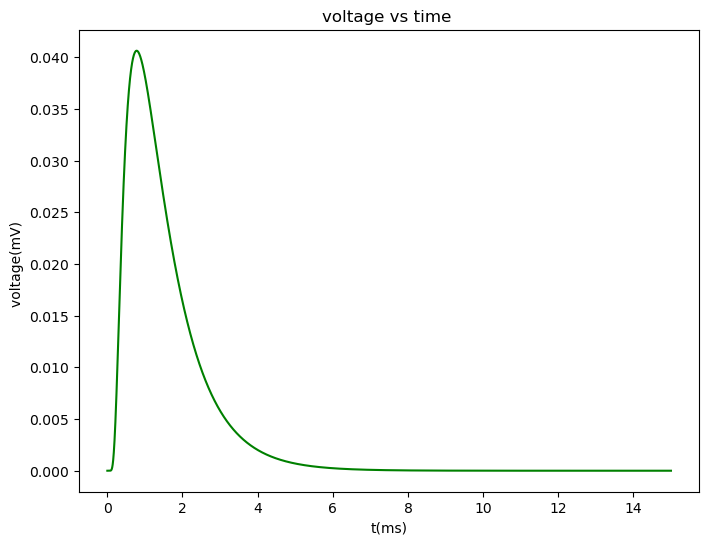

In [22]:
#  Passive Cable
import numpy as np
import matplotlib.pyplot as plt
dt = 0.001
volt = []
Time = []
x = 2 # at arbitory loction from the point of current injection
fig, ax = plt.subplots(figsize=(8,6))

for t in range(1, 15000):
    # change in voltage as time passes on a particular location on dendrite (green function)
    u = np.exp(-t*dt - ((x)**2)/(4*t*dt))*(4*np.pi*t*dt)**(-1/2)
    volt.append(u)
    time = t*dt
    Time.append(time)
        
ax.plot(Time, volt, color = "green")
ax.set_title("voltage vs time ")
ax.set_xlabel("t(ms)")
ax.set_ylabel("voltage(mV) ")
plt.show()          
        

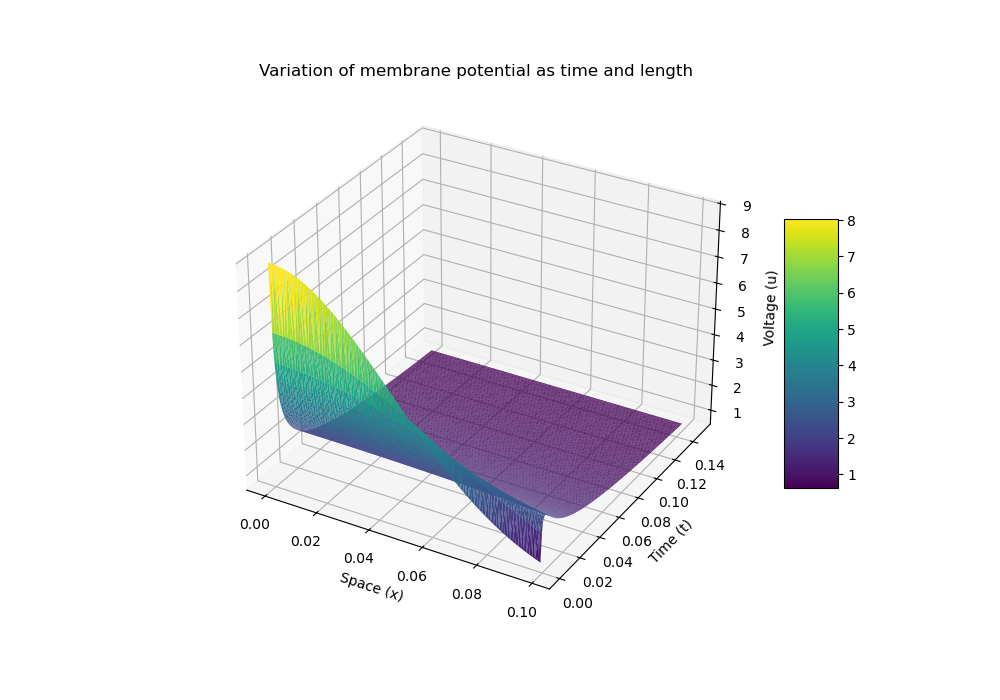

In [27]:
#  Passive Cable : change in voltage as function of time and postion(from the injection point of current)
%matplotlib ipympl
import numpy as np
import matplotlib.pyplot as plt

dt = 0.001 # time step
dx = 0.001 # position step
volt =  [] 
Time = []
coord = [] # holder for position

for t in range(1, 150):
    for x in range(100):
        X =x*dx
        coord.append(X)
        u = np.exp(-t*dt - ((x*dx)**2)/(4*t*dt))*(4*np.pi*t*dt)**(-1/2) # green function
        volt.append(u)
        time = t*dt
        Time.append(time)
        
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_trisurf(coord, Time, volt, cmap='viridis', edgecolor='none')

ax.set_xlabel('Space (x)')
ax.set_ylabel('Time (t)')
ax.set_zlabel('Voltage (u)')
ax.set_title('Variation of membrane potential as time and length')
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.show()
        


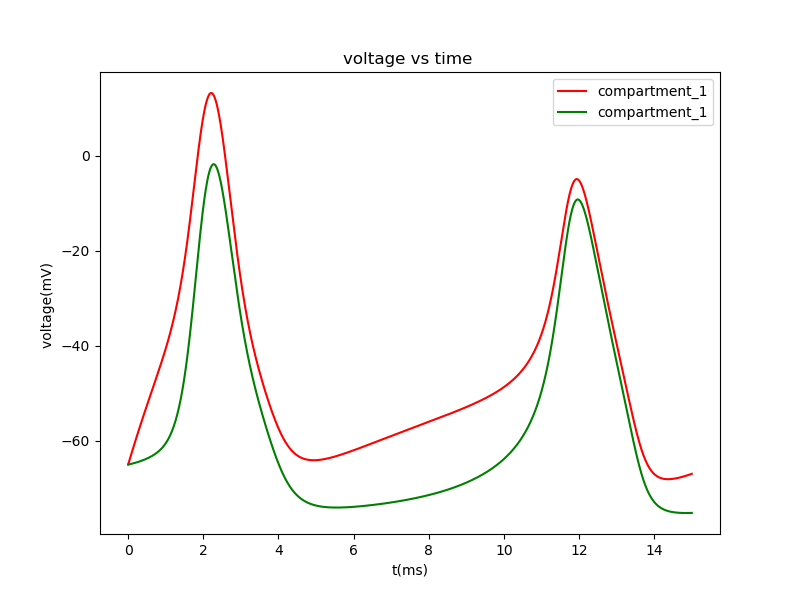

In [28]:
#Compartmental model with hh model 
import numpy as np
import matplotlib.pyplot as plt
# max conductance of ion channels
g_Na = 120
g_K = 36
dt = 0.001 # time step
# Initation of voltage
V_1 = -65 + 1e-6
V_2 = -65 + 1e-6
E_Na = 50 # in mV 
E_K =-77  # in mV
E_L = -54.4 # in mV
T = -55 # Threshold
R = -65 # Resting potential
# # Maximum activity of gating variable at rest
M = 0.0498
N = 0.00045
H = 0.0302
M2 = 0.0498
N2 = 0.00045
H2 = 0.0302
# Holders
Time = []
Volt_1 = []
Volt_2 = []
# Membrance capacitance at each compartment
C_1 = 2
C_2 = 2.01
# conductance through ion channels other than Na and K
g_1 = 0.3
g_2 = 0.303
g = 0.301 # Conductance of ion channel which present between both compartment 
I = 50 # Constant current supplied to compartment 1

for t in range(15000):
    time  = t*dt
    Time.append(time)
    #1st compartment
    
    alpha_m = 0.1 * (V_1 + 40) / (1 - np.exp(-(V_1 + 40) / 10))
    beta_m = 4.0 * np.exp(-(V_1 + 65) / 18)

    alpha_n = 0.01 * (V_1 + 55) / (1 - np.exp(-(V_1 + 55) / 10))
    beta_n = 0.125 * np.exp(-(V_1 + 65) / 80)

    alpha_h = 0.07 * np.exp(-(V_1 + 65) / 20)
    beta_h = 1.0 / (1.0 + np.exp(-(V_1 + 35) / 10))
    T_m = 1/ (alpha_m + beta_m)
    T_n = 1/ (alpha_n + beta_n)
    T_h = 1/ (alpha_h + beta_h)
    
    m = alpha_m/(alpha_m + beta_m)
    n = alpha_n/(alpha_n + beta_n)
    h = alpha_h/(alpha_h + beta_h)

    M = m + (M - m) * np.exp(-dt / T_m)
    N = n + (N - n) * np.exp(-dt / T_n)
    H = h + (H - h) * np.exp(-dt / T_h)
    # Current leaking through ion channels
    I_Na1 =  g_Na*M**3*H*(V_1 - E_Na)
    I_K1 = g_K*N**4*(V_1 - E_K)
    

    #2 COMPARTMENT

    alpha_m2 = 0.1 * (V_2 + 40) / (1 - np.exp(-(V_2 + 40) / 10))
    beta_m2 = 4.0 * np.exp(-(V_2 + 65) / 18)

    alpha_n2 = 0.01 * (V_2 + 55) / (1 - np.exp(-(V_2 + 55) / 10))
    beta_n2 = 0.125 * np.exp(-(V_2 + 65) / 80)

    alpha_h2 = 0.07 * np.exp(-(V_2 + 65) / 20)
    beta_h2 = 1.0 / (1.0 + np.exp(-(V_2 + 35) / 10))
    T_m2 = 1/ (alpha_m2 + beta_m2)
    T_n2 = 1/ (alpha_n2 + beta_n2)
    T_h2 = 1/ (alpha_h2 + beta_h2)
    
    m2 = alpha_m2/(alpha_m2 + beta_m2)
    n2 = alpha_n2/(alpha_n2 + beta_n2)
    h2 = alpha_h2/(alpha_h2 + beta_h2)
    
    M2 = m2 + (M2 - m2) * np.exp(-dt / T_m2)
    N2 = n2 + (N2 - n2) * np.exp(-dt / T_n2)
    H2 = h2 + (H2 - h2) * np.exp(-dt / T_h2)
    # Current leaking through ion channels
    I_Na2 =  g_Na*M**3*H*(V_2 - E_Na)
    I_K2 = g_K*N**4*(V_2 - E_K)

    
    IL_1 = g_1*(V_1- E_L)
    IL_2 = g_2*(V_2 - E_L)
    
    I_axial = g*(V_1 - V_2) #Current flowing between compartment 1 and compartment 2 due to potential difference 
    # voltage differential equations
    dV_1 = (1/C_1)*(I - I_Na1 - I_K1 -IL_1 - I_axial)*dt
    V_1+=dV_1
    Volt_1.append(V_1)
    dV_2 = (1/C_2)*( - I_Na2 - I_K2 -IL_2 + I_axial)*dt
    V_2+=dV_2
    Volt_2.append(V_2)
    
fig, ax = plt.subplots(figsize=(8,6))
ax.plot(Time, Volt_1, label = "compartment_1", color = "red")
ax.plot(Time, Volt_2, label = "compartment_1", color = "green")
ax.set_title("voltage vs time ")
ax.set_xlabel("t(ms)")
ax.set_ylabel("voltage(mV) ")
plt.legend()
plt.show()
    


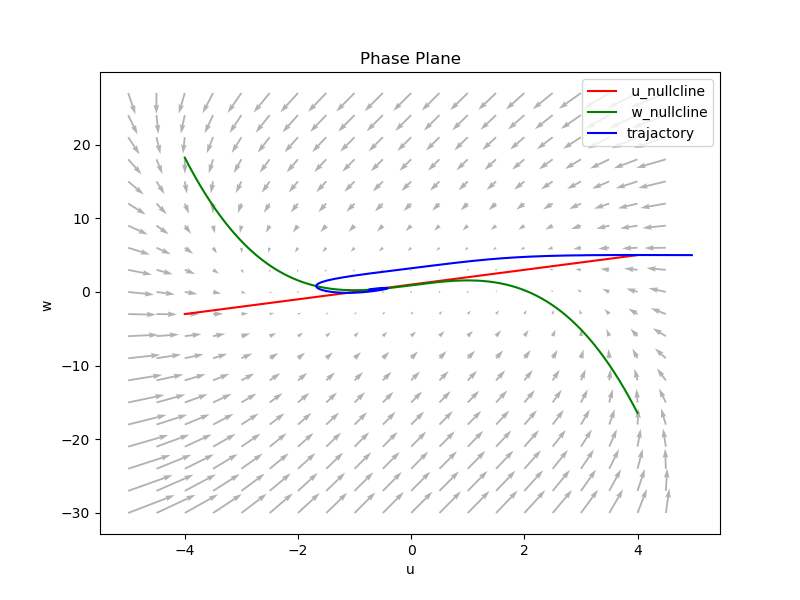

In [29]:
# Dimensionality reduction and phase plane analysis ( FitzHugh–Nagumo model)
import numpy as np
import matplotlib.pyplot as plt
plt.close('all')

i = 0.9 # current
b = 1
# Holders to generate nullclines
W_1 = [] 
W_2 = []
U_1 = []
U_2 = []
volt = []
net = []
# Intial co-ordinates for trajectory
u_1 = 5
w_1 = 8.3
dt =  0.001
fig, ax = plt.subplots(figsize=(8,6))
# 1. nullclines
for u in np.arange(-4, 4, 0.001):
    w_1 = u + 1
    W_1.append(w_1)
    w_2 = u * b - (1/3) * (u * b)**3 + i
    W_2.append(w_2)
    U_2.append(u * b)
    U_1.append(u)

# 2.Trajactory
for t in range(50000):
    du = (u_1 - (1/3)*u_1**3 - w_1 + i ) * dt
    dw = (u_1 + 1 - w_1) * dt
    u_1 += du
    volt.append(u_1)
    w_1 += dw
    net.append(w_1)
    # Vector field
    
u_coords = []
w_coords = []
du_vectors = []
dw_vectors = []

for u in np.arange(-5, 5, 0.5):
   
    for w in np.arange(-30, 30, 3):
        
      
        du = (u - (1/3)*(u**3) - w + i)
        dw = (u + 1 - w)
        
        
        u_coords.append(u)
        w_coords.append(w)
        du_vectors.append(du)
        dw_vectors.append(dw)

#  arrows across the map
ax.quiver(u_coords, w_coords, du_vectors, dw_vectors, color='gray', alpha=0.6)



ax.plot(U_1, W_1, label = " u_nullcline", color="red")
ax.plot(U_2, W_2,  label = " w_nullcline", color="green")
ax.plot(volt, net,  label = "trajactory",  color="blue")
ax.set_title("Phase Plane")
ax.set_xlabel("u")
ax.set_ylabel("w ")
plt.legend()
plt.show()

    

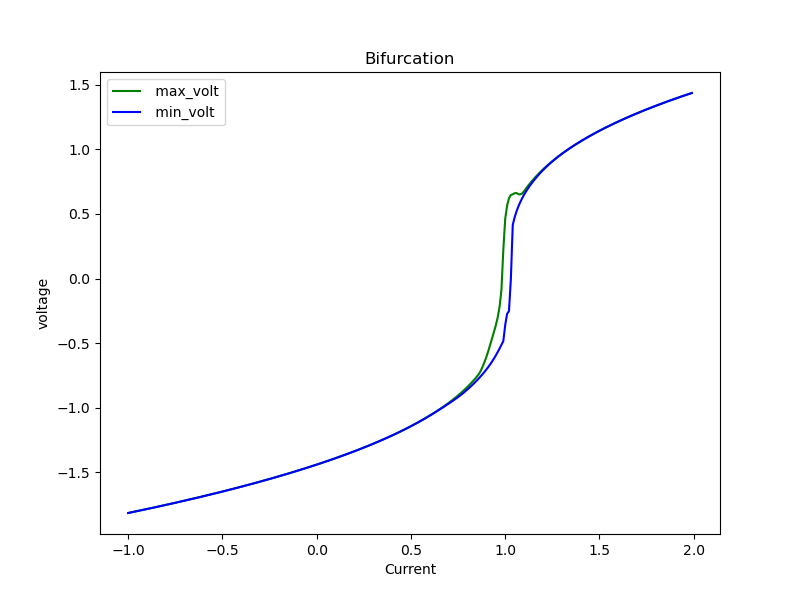

In [26]:
# Bifurcation diagram : Analysis of threshold in case of  FitzHugh–Nagumo model 
import numpy as np
import matplotlib.pyplot as plt
plt.close('all')

max_volt=[]
min_volt = []
current = []
fig, ax = plt.subplots(figsize=(8,6))

for i in np.arange(-1.0, 2, 0.01):
    volt = []
    current.append(i)
    u_1 = 0
    w_1 = 0
    dt =  0.01
    for t in range(8000):
        du = (u_1 - (1/3)*u_1**3 - w_1 + i ) * dt
        dw = (u_1 + 1 - w_1) * dt
        u_1 += du
        volt.append(u_1)
        w_1 += dw
    steady = volt[1500:]  # to cut out intial messy data  
    max_volt.append(max(steady))
    min_volt.append(min(steady))   
    

ax.plot(current, max_volt, label = " max_volt", color="green")
ax.plot(current, min_volt, label = " min_volt", color="blue")
ax.set_title("Bifurcation")
ax.set_xlabel("Current")
ax.set_ylabel("voltage")
plt.legend()
plt.show()

